<a href="https://colab.research.google.com/github/vzavala/DoE/blob/main/Python/ch5_hougen_watson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the course's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('doe'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DoE.git doe')
        os.system('git -C doe sparse-checkout set Python/Data Python/Support')
    path = 'doe/Python/'

Nonlinear estimation for the Hougen-Watson model (Victor Z and Leo Gonzalez, UW-Madison, 2024).

$$m_\omega(\theta)=\frac{\theta_0x_{2,\omega}-x_{3,\omega}/\theta_4}{1+\theta_1x_{1,\omega}+\theta_2x_{2,\omega}+\theta_3x_{3,\omega}}$$

| Slides | Python | Meaning |
|---|---|---|
| $x_{1,\omega},x_{2,\omega},x_{3,\omega}$ | `X[:, 0]`, `X[:, 1]`, `X[:, 2]` | partial pressures ($S=13$ experiments) |
| $y_\omega$ | `y` | reaction rate |
| $\theta=(\theta_0,\dots,\theta_4)$ | `theta[0]`, ..., `theta[4]` | parameters |
| $m(\theta)$, $SSE(\theta)=\frac{1}{2}\lVert\mathbf{y}-\mathbf{m}(\theta)\rVert^2$ | `m(theta, X)`, `SSE(theta)` | model and objective |

**Note:** This notebook reproduces Example 5.10 (Section 5.3) of *Statistics for Chemical Engineers*: nonlinear estimation of a Hougen-Watson rate model.

**The concept.** When the model is nonlinear in the parameters, $\mathbf{m}(\theta)$, there is no closed-form estimate. We minimize $SSE(\theta)=\frac{1}{2}\lVert\mathbf{y}-\mathbf{m}(\theta)\rVert^2$ iteratively. With the Jacobian $\mathcal{J}=\nabla_\theta\mathbf{m}(\theta)$ (one row per experiment, one column per parameter),

$$\nabla_\theta SSE=-\mathcal{J}^T(\mathbf{y}-\mathbf{m}(\theta)),\qquad \mathcal{H}\approx\mathcal{J}^T\mathcal{J}.$$

The Gauss-Newton step solves $\mathcal{J}^T\mathcal{J}\,\Delta\theta=\mathcal{J}^T(\mathbf{y}-\mathbf{m})$, and Levenberg-Marquardt adds damping, $(\mathcal{J}^T\mathcal{J}+\mu I)\Delta\theta=\mathcal{J}^T(\mathbf{y}-\mathbf{m})$, to stay safe when $\mathcal{J}^T\mathcal{J}$ is nearly singular. Since $SSE$ is not convex, the result can depend on the initial guess.

## The SSE function is highly nonlinear

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

data = np.loadtxt(path+'Data/hougenwatson.dat')
X, y = data[:, :3], data[:, -1]
S = len(y)

def m(theta, X):
    """Hougen-Watson model m(theta, x) for all rows of X."""
    x1, x2, x3 = X[:, 0], X[:, 1], X[:, 2]
    return (theta[0]*x2 - x3/theta[4]) / (1 + theta[1]*x1 + theta[2]*x2 + theta[3]*x3)

def SSE(theta):
    return 0.5 * np.sum((y - m(theta, X))**2)

$SSE(\theta)$ as we span $\theta_1,\theta_2\in[-2,2]$ (other parameters fixed at a reference value).
Note the poles where the denominator of $m$ vanishes.

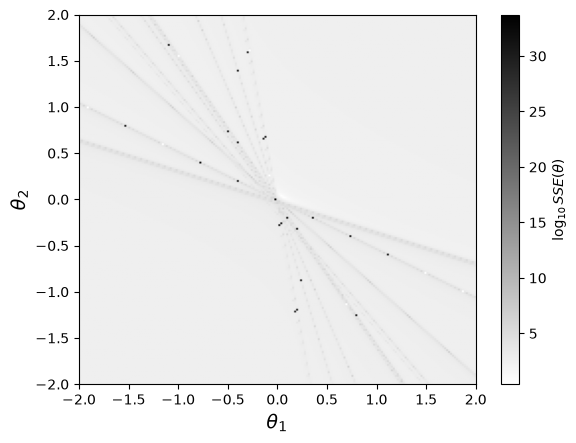

In [3]:
theta_ref = np.array([1.0, 0.05, 0.02, 0.1, 2.0])
grid = np.linspace(-2, 2, 201)
SSE_map = np.zeros((len(grid), len(grid)))
# the model has a pole where its denominator is zero; those grid points give SSE = inf (left blank in the plot)
with np.errstate(divide='ignore', invalid='ignore'):
    for i, t2 in enumerate(grid):
        for j, t1 in enumerate(grid):
            th = theta_ref.copy()
            th[1], th[2] = t1, t2
            SSE_map[i, j] = SSE(th)
with np.errstate(divide='ignore'):
    log_SSE = np.log10(SSE_map)
plt.imshow(log_SSE, extent=[-2, 2, -2, 2], origin='lower', cmap='gray_r', aspect='auto')
plt.colorbar(label=r'$\log_{10} SSE(\theta)$')
plt.xlabel(r'$\theta_1$', fontsize=14)
plt.ylabel(r'$\theta_2$', fontsize=14)
plt.show()

## Good and bad initial guesses

Solve $\min_\theta \frac{1}{2}\lVert\mathbf{y}-\mathbf{m}(\theta)\rVert^2$ with a Levenberg-Marquardt
(Newton-like) method, from $\theta=(1,\dots,1)$ and from $\theta=(-1,\dots,-1)$.
(The slides use Matlab's `fitnlm`; `scipy.optimize.least_squares` plays the same role.)
As in the book, the reported value is the sum of squared residuals (without the factor 1/2).

theta0 = (1,...,1):  theta_hat = [1.25 0.06 0.04 0.11 1.19],  SSE = 0.2989
theta0 = (-1,...,-1):  theta_hat = [-4820718.59  -306012.27   -98248.06 -1089977.83    16491.51],  SSE = 11.3903


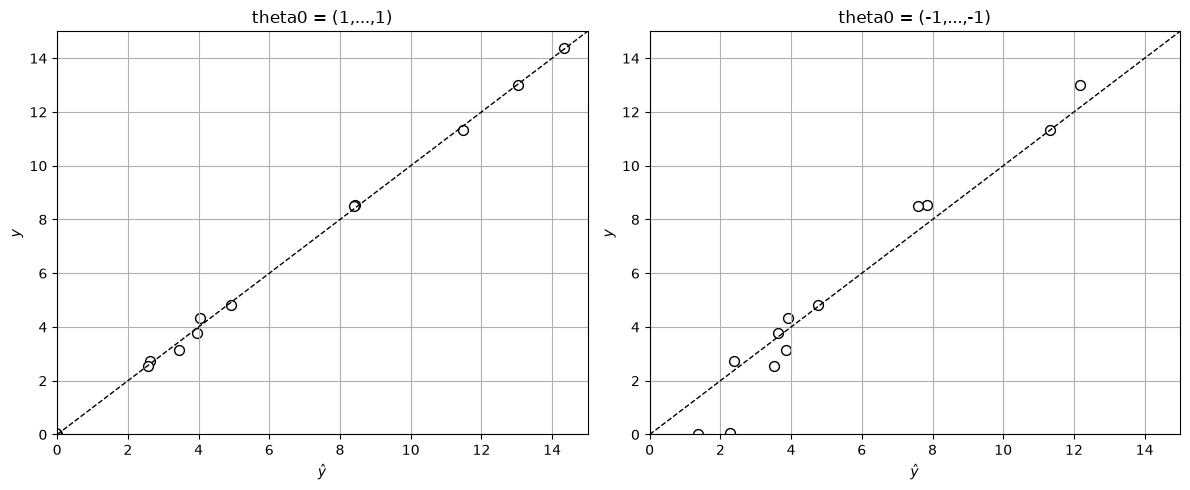

In [4]:
fits = {}
for label, theta0 in (("theta0 = (1,...,1)", np.ones(5)), ("theta0 = (-1,...,-1)", -np.ones(5))):
    sol = least_squares(lambda th: y - m(th, X), theta0, method='lm', max_nfev=2000)
    fits[label] = sol.x
    print(f"{label}:  theta_hat = {np.round(sol.x, 2)},  SSE = {2*SSE(sol.x):.4f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (label, th) in zip(axs, fits.items()):
    ax.plot([0, 15], [0, 15], 'k--', linewidth=1)
    ax.scatter(m(th, X), y, marker='o', color='w', edgecolor='k', s=50)
    ax.set_title(label)
    ax.set_xlabel(r'$\hat{y}$'); ax.set_ylabel('$y$')
    ax.axis([0, 15, 0, 15])
    ax.grid(True)
plt.tight_layout()
plt.show()

**The math, from scratch.** A minimal Levenberg-Marquardt method: a step that lowers $SSE$ is accepted and the damping $\mu$ is reduced; otherwise $\mu$ is increased. The Jacobian follows from the quotient rule. With $N=\theta_0x_2-x_3/\theta_4$ and $D=1+\theta_1x_1+\theta_2x_2+\theta_3x_3$,

$$\mathcal{J}=\left[\frac{x_2}{D},\;-\frac{N x_1}{D^2},\;-\frac{N x_2}{D^2},\;-\frac{N x_3}{D^2},\;\frac{x_3}{\theta_4^2D}\right].$$

In [5]:
def jac(theta):
    x1, x2, x3 = X.T
    N, D = theta[0]*x2 - x3/theta[4], 1 + theta[1]*x1 + theta[2]*x2 + theta[3]*x3
    return np.column_stack([x2/D, -N*x1/D**2, -N*x2/D**2, -N*x3/D**2, x3/(theta[4]**2 * D)])

theta, mu = np.ones(5), 1.0
for it in range(500):
    J, r = jac(theta), y - m(theta, X)
    step = np.linalg.solve(J.T @ J + mu * np.eye(5), J.T @ r)
    if SSE(theta + step) < SSE(theta):
        theta, mu = theta + step, mu / 3
    else:
        mu *= 3
    if np.linalg.norm(step) < 1e-9:
        break
print(f"from scratch: theta = {np.round(theta, 2)},  SSE = {2*SSE(theta):.4f}")
print(f"scipy:        theta = {np.round(fits['theta0 = (1,...,1)'], 2)},  SSE = {2*SSE(fits['theta0 = (1,...,1)']):.4f}")

from scratch: theta = [1.25 0.06 0.04 0.11 1.19],  SSE = 0.2989
scipy:        theta = [1.25 0.06 0.04 0.11 1.19],  SSE = 0.2989


**Note:** As in the book, the SSE function is highly nonlinear: a good initial guess helps, but nothing prevents the solver from landing on estimates with no physical meaning.